# 02 Baselines: median and matrix pricing

Three baselines, all from `src/ml2/baseline.py`, so every notebook compares against the same definitions.

Class notebooks followed: `Regression_Improve Bagg & RF with Boosting` ("0. Baseline model: median value").

Validation months only: the test months are scored once, in `99_final`. Runs top to bottom in about 2 minutes; figures go to
`reports/figures/02_*.png`.

In [1]:
# Deck style for every figure: IG is always teal, HY always orange
import matplotlib.pyplot as plt

DECK = {"teal": "#114A6B", "orange": "#FF5F00", "slate": "#3A4550", "grey": "#8A949C", "pale": "#DCE6EC"}
plt.rcParams.update({
    "font.family": "Arial", "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": DECK["grey"], "axes.labelcolor": DECK["slate"], "axes.titleweight": "bold",
    "axes.titlecolor": DECK["teal"],
    "axes.prop_cycle": plt.cycler(color=[DECK["teal"], DECK["orange"], DECK["grey"], DECK["slate"]]),
    "xtick.color": DECK["slate"], "ytick.color": DECK["slate"], "axes.grid": True, "axes.grid.axis": "y",
    "axes.axisbelow": True, "grid.color": DECK["pale"],
    "figure.figsize": (10, 5.6), "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})

## 1. Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from ml2.baseline import fit_matrix_frozen, matrix_same_date, median_baseline, predict_matrix_frozen
from ml2.config import load_config, resolve
from ml2.data import check_panel, load_panel
from ml2.evaluate import metrics_by_stratum

cfg = load_config()
TARGET = cfg["problem"]["target"]
FIG = resolve("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
MATURITY_ORDER = ["1-3y", "3-5y", "5-7y", "7-10y", "10-20y", "20y+"]

check_panel()
df = load_panel(partitions=["train", "valid"])
train = df[df.partition == "train"]
valid = df[df.partition == "valid"].copy()
print(f"train {len(train):,} rows, valid {len(valid):,} rows")

train 119,456 rows, valid 28,569 rows


## 2. Class baseline: the median

As in the class notebook ("0. Baseline model: median value"): predict the median training spread for every bond.
One number for everything, so it ignores grade and maturity.

In [3]:
valid["pred_median"] = median_baseline(train, valid)
print(f"median training spread: {valid['pred_median'].iloc[0]:.1f} bp")
metrics_by_stratum(valid, TARGET, "pred_median", "grade_bucket").round(1)

median training spread: 88.7 bp


,stratum,n,mae_bps,rmse_bps,medae_bps,r2
0,HY,2149,126.9,200.4,82.7,-0.6
1,IG,26420,29.8,38.3,25.3,-0.1
2,ALL,28569,37.1,66.2,27.0,-0.0


## 3. Matrix pricing, frozen

The pricing desk's rule: the median spread of bonds in the same grade x maturity bucket x sector cell, falling
back to grade x maturity, then grade, when a cell has fewer than 20 bonds. Frozen: the medians come from the
training months only. Reference row.

In [4]:
valid["pred_matrix_frozen"] = predict_matrix_frozen(fit_matrix_frozen(train), valid)
metrics_by_stratum(valid, TARGET, "pred_matrix_frozen", "grade_bucket").round(1)

,stratum,n,mae_bps,rmse_bps,medae_bps,r2
0,HY,2149,86.1,153.1,56.7,0.1
1,IG,26420,23.2,32.0,19.2,0.2
2,ALL,28569,27.9,52.1,20.3,0.4


## 4. Matrix pricing, re-marked each date

What a desk actually does: on each snapshot date, a bond is priced from the same-date spreads of **other
companies'** bonds in its cell (its own company is left out, so it never prices itself). This is the gate
baseline: the final model must beat it by at least 10% in IG and in HY. About 1.5 minutes.

In [5]:
valid["pred_matrix_same_date"] = matrix_same_date(valid)
metrics_by_stratum(valid, TARGET, "pred_matrix_same_date", "grade_bucket").round(1)

,stratum,n,mae_bps,rmse_bps,medae_bps,r2
0,HY,2149,88.4,163.3,48.6,-0.1
1,IG,26420,21.2,31.9,14.9,0.2
2,ALL,28569,26.2,54.3,16.0,0.3


## 5. Baseline numbers

All three, by grade and by maturity bucket.

In [6]:
BASELINES = {
    "pred_median": "Median spread (class baseline)",
    "pred_matrix_frozen": "Matrix pricing, frozen at the training months",
    "pred_matrix_same_date": "Matrix pricing, re-marked each date (gate baseline)",
}
by_grade = pd.concat({name: metrics_by_stratum(valid, TARGET, col, "grade_bucket").set_index("stratum")
                      for col, name in BASELINES.items()})
by_grade[["n", "mae_bps", "rmse_bps", "medae_bps", "r2"]].round(2)

n  mae_bps  rmse_bps  medae_bps    r2
                                                    stratum                                           
Median spread (class baseline)                      HY        2149   126.92    200.35      82.70 -0.61
                                                    IG       26420    29.78     38.31      25.30 -0.13
                                                    ALL      28569    37.09     66.15      27.03 -0.00
Matrix pricing, frozen at the training months       HY        2149    86.07    153.10      56.65  0.06
                                                    IG       26420    23.18     32.03      19.19  0.21
                                                    ALL      28569    27.91     52.08      20.35  0.38
Matrix pricing, re-marked each date (gate baseline) HY        2149    88.36    163.30      48.58 -0.07
                                                    IG       26420    21.18     31.94      14.92  0.21
                                                    ALL      28569    26.23     54.31      15.96  0.32

,Median spread (class baseline),"Matrix pricing, frozen at the training months","Matrix pricing, re-marked each date (gate baseline)"
stratum,,,
1-3y,51.3,25.9,25.7
3-5y,47.2,31.3,30.8
5-7y,37.2,29.8,28.2
7-10y,28.8,27.6,25.3
10-20y,31.0,29.1,26.9
20y+,22.4,24.3,20.5


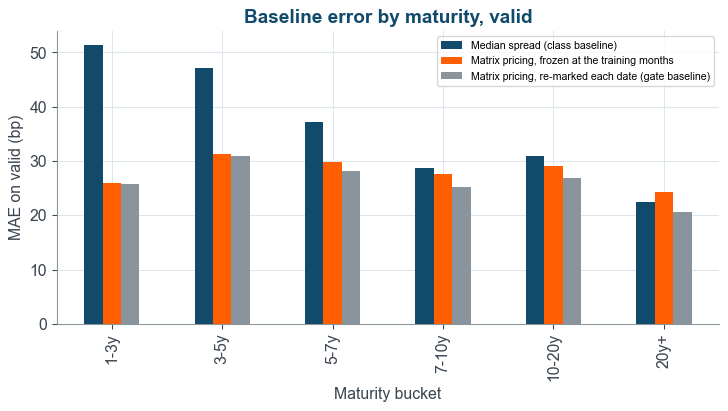

In [7]:
by_maturity = pd.DataFrame({
    name: metrics_by_stratum(valid, TARGET, col, "maturity_bucket").set_index("stratum")["mae_bps"]
    for col, name in BASELINES.items()
}).loc[MATURITY_ORDER]

fig, ax = plt.subplots(figsize=(9, 4))
by_maturity.plot.bar(ax=ax)
ax.set_xlabel("Maturity bucket"); ax.set_ylabel("MAE on valid (bp)")
ax.set_title("Baseline error by maturity, valid"); ax.legend(fontsize=8)
fig.savefig(FIG / "02_mae_by_maturity.png", dpi=150, bbox_inches="tight")
by_maturity.round(1)

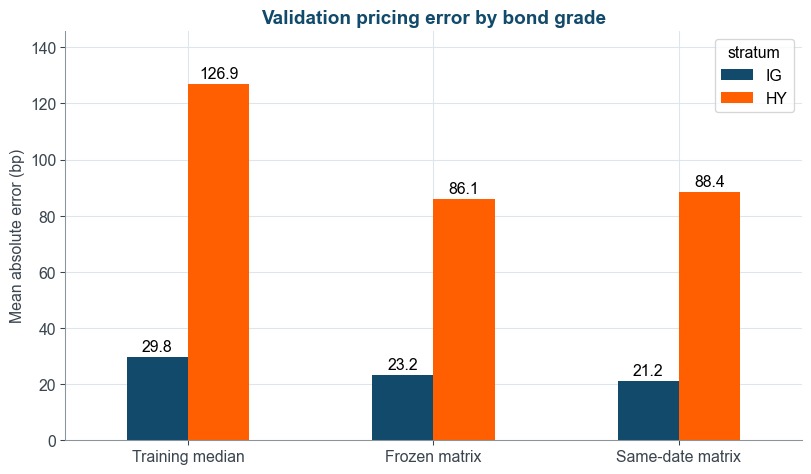

In [8]:
grade_mae = by_grade["mae_bps"].unstack("stratum")[["IG", "HY"]].copy()
grade_mae.index = ["Training median", "Frozen matrix", "Same-date matrix"]
ax = grade_mae.plot.bar(rot=0, color=[DECK["teal"], DECK["orange"]])
ax.set_title("Validation pricing error by bond grade")
ax.set_xlabel("")
ax.set_ylabel("Mean absolute error (bp)")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=2)
ax.margins(y=0.15)
ax.figure.savefig(FIG / "02_mae_by_grade.png", dpi=150, bbox_inches="tight")

Re-marking the matrix each date reduced overall mean absolute error from 27.9 to 26.2 bp. IG improved from 23.2 to 21.2 bp. HY moved the other way, from 86.1 to 88.4 bp, even though its median absolute error fell from 56.7 to 48.6 bp. Typical HY predictions improved, but large misses outweighed those gains in the mean. Its 163.3 bp RMSE also reflects the larger penalty on those misses. IG accounts for 92.5% of validation observations, so the pooled result is dominated by IG.

The same-date matrix is the agreed benchmark. The final model must cut MAE by at least 10% in each grade, with the issuer-bootstrap interval for improvement above zero. These validation results establish the comparison for model development.

## 6. Run-log verification

Rounded validation MAEs reproduce the three baseline entries recorded for panel `d817a09a` in `RUN_LOG.md`.

In [9]:
# Compare the validation results with the three entries for panel d817a09a in RUN_LOG.md.
by_grade["mae_bps"].unstack("stratum")[["IG", "HY", "ALL"]].round(1)

stratum,IG,HY,ALL
Median spread (class baseline),29.8,126.9,37.1
"Matrix pricing, frozen at the training months",23.2,86.1,27.9
"Matrix pricing, re-marked each date (gate baseline)",21.2,88.4,26.2
